
# Principal Component Regression (PCR)

## 1. Covariance — Quick Recap

Covariance measures how two variables change together.

$$
\boxed{
\operatorname{Cov}(X_r,X_s)
=E[(X_r-\mu_r)(X_s-\mu_s)]
}
$$

- **Positive:** Variables tend to move together.
- **Negative:** Variables tend to move in opposite directions.
- **Zero:** No linear relationship.

### Covariance Matrix

For $p$ predictors:

$$
\boxed{
\Sigma=E[(X-\mu)(X-\mu)^T]
}
$$

- $\Sigma$ is a $p\times p$ matrix.
- Diagonal entries = variances.
- Off-diagonal entries = covariances.
- If $E[X]=0$, then $\Sigma=E[XX^T]$.

## 2. Principal Component Regression (PCR)

**Goal:** Replace $p$ original predictors with $M<p$ artificial predictors (principal components).

Each new variable is a linear combination:

$$
\boxed{
Z_m=\phi_m^TX=\sum_{j=1}^{p}\phi_{mj}X_j
}
$$

Where:
- $Z_m$: New artificial predictor.
- $\phi_{mj}$: Weight assigned to original predictor $X_j$.
- $M<p$: Dimensionality reduction.

**Matrix form:**

$$
\boxed{Z=\Phi X}
$$

- $\Phi$: $M\times p$ transformation matrix.
- $X$: $p\times 1$ original input vector.
- $Z$: $M\times 1$ transformed input vector.

Then perform linear regression using $Z_1,\ldots,Z_M$ instead of the original $p$ predictors.

## 3. How Do We Choose the Components?

**PCR chooses directions that maximize variance** in the input data.

Example: If $X_1\approx X_2$ (strong positive correlation):

$$
Z_1=X_1+X_2 \quad \text{(High variance)}
$$

$$
Z_2=X_1-X_2 \approx 0 \quad \text{(Low variance)}
$$

- **High variance:** Captures more variation in the predictors.
- **Low variance:** Captures little variation in the predictors.
- PCA chooses orthogonal directions in descending order of variance.

**Important:** High predictor variance does not always mean high predictive power for $Y$. PCR selects components without looking at $Y$.

## 4. Key Takeaways

1. Covariance measures how predictors vary together.
2. PCR replaces $p$ predictors with $M<p$ principal components.
3. Each component is a weighted sum of original predictors.
4. PCA prioritizes directions with maximum variance.
5. PCR performs linear regression on the selected components.
6. Components should be computed using training data only to avoid data leakage.

## Quick Understanding Check

1. Why is $X_1-X_2$ a poor component when $X_1\approx X_2$?
2. What does a large variance tell us about a principal component?
3. If we have 10 predictors and keep 3 components, how many predictors enter the regression?
4. Does maximizing variance guarantee better prediction of $Y$?


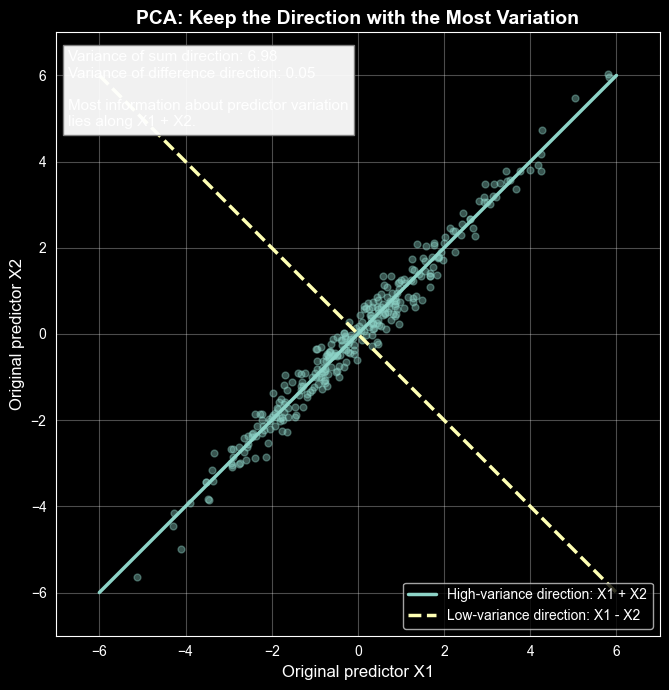

In [2]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

x1 = rng.normal(0, 2, 300)
x2 = x1 + rng.normal(0, 0.3, 300)

# Normalize directions for fair variance comparison
z_sum = (x1 + x2) / np.sqrt(2)
z_diff = (x1 - x2) / np.sqrt(2)

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(x1, x2, alpha=0.4, s=24)

t = np.linspace(-6, 6, 100)
ax.plot(t, t, linewidth=2.5, label="High-variance direction: X1 + X2")
ax.plot(t, -t, linewidth=2.5, linestyle="--",
        label="Low-variance direction: X1 - X2")

ax.set_title(
    "PCA: Keep the Direction with the Most Variation",
    fontsize=14, weight="bold"
)
ax.set_xlabel("Original predictor X1", fontsize=12)
ax.set_ylabel("Original predictor X2", fontsize=12)

ax.text(
    0.02, 0.97,
    f"Variance of sum direction: {np.var(z_sum):.2f}\n"
    f"Variance of difference direction: {np.var(z_diff):.2f}\n\n"
    "Most information about predictor variation\n"
    "lies along X1 + X2.",
    transform=ax.transAxes,
    va="top", fontsize=11,
    bbox=dict(facecolor="white", alpha=0.95, edgecolor="gray")
)

ax.set_xlim(-7, 7)
ax.set_ylim(-7, 7)
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


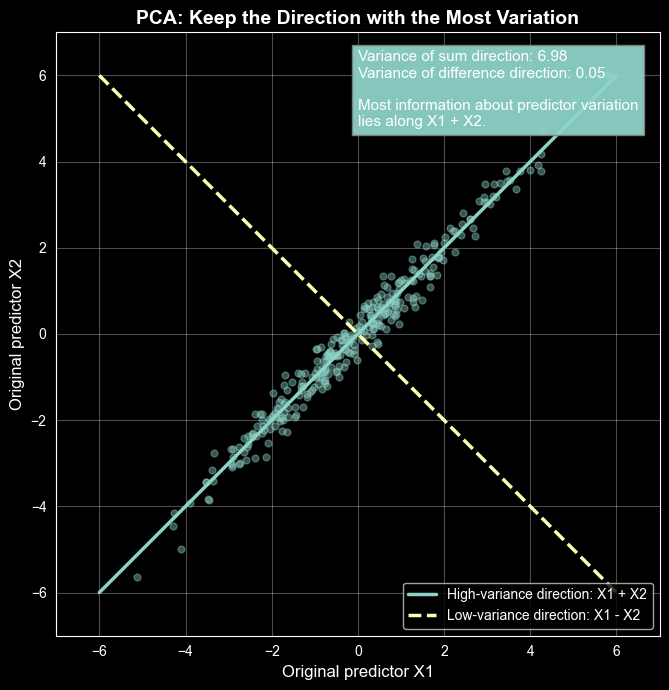

In [6]:

import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

x1 = rng.normal(0, 2, 300)
x2 = x1 + rng.normal(0, 0.3, 300)

# Normalize directions for fair variance comparison
z_sum = (x1 + x2) / np.sqrt(2)
z_diff = (x1 - x2) / np.sqrt(2)

fig, ax = plt.subplots(figsize=(11, 7))

ax.scatter(x1, x2, alpha=0.4, s=24)

t = np.linspace(-6, 6, 100)
ax.plot(t, t, linewidth=2.5, label="High-variance direction: X1 + X2")
ax.plot(t, -t, linewidth=2.5, linestyle="--",
        label="Low-variance direction: X1 - X2")

ax.set_title(
    "PCA: Keep the Direction with the Most Variation",
    fontsize=14, weight="bold"
)
ax.set_xlabel("Original predictor X1", fontsize=12)
ax.set_ylabel("Original predictor X2", fontsize=12)

ax.text(
    0.5, 0.97,
    f"Variance of sum direction: {np.var(z_sum):.2f}\n"
    f"Variance of difference direction: {np.var(z_diff):.2f}\n\n"
    "Most information about predictor variation\n"
    "lies along X1 + X2.",
    transform=ax.transAxes,
    va="top", fontsize=11,
    bbox=dict(alpha=0.95, edgecolor="gray")
)

ax.set_xlim(-7, 7)
ax.set_ylim(-7, 7)
ax.set_aspect("equal")
ax.legend(loc="lower right", fontsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


## PCA: Choosing the First Principal Component
### Goal

Create one new variable, called the first principal component, as a weighted combination of the original inputs:

$$
Z_1 = \boldsymbol{\phi}_1^T \mathbf{X}
$$

Here, $\boldsymbol{\phi}_1$ contains the weights. We want the direction that preserves the most variation in the data.

### Variance of the new variable

Assume the inputs have mean zero, so their covariance matrix is
$\boldsymbol{\Sigma} = \operatorname{Cov}(\mathbf{X})$.

$$
\begin{aligned}
\operatorname{Var}(Z_1)
&= \operatorname{Var}(\boldsymbol{\phi}_1^T\mathbf{X}) \\
&= \mathbb{E}\left[(\boldsymbol{\phi}_1^T\mathbf{X})^2\right] \\
&= \boldsymbol{\phi}_1^T
   \mathbb{E}[\mathbf{X}\mathbf{X}^T]
   \boldsymbol{\phi}_1 \\
&= \boldsymbol{\phi}_1^T\boldsymbol{\Sigma}\boldsymbol{\phi}_1
\end{aligned}
$$

The weights are constants, so they can be moved outside the expectation.

### Optimization

If the weights could grow without limit, the variance could also grow without limit. PCA prevents this by requiring the weight vector to have length 1:

$$
\|\boldsymbol{\phi}_1\|_2 = 1
$$

Then it chooses the weights that **maximize** the variance:

$$
\boldsymbol{\phi}_1^*
=
\underset{\|\boldsymbol{\phi}_1\|_2=1}{\operatorname{argmax}}
\ \boldsymbol{\phi}_1^T\boldsymbol{\Sigma}\boldsymbol{\phi}_1
$$

The solution is the unit eigenvector of $\boldsymbol{\Sigma}$ corresponding to its largest eigenvalue:

$$
\boldsymbol{\phi}_1^* = \mathbf{v}_1
$$

The eigenvalue $\lambda_1$ tells us how much variance this component captures:

$$
\operatorname{Var}(Z_1) = \lambda_1
$$

### Intuition

Imagine projecting a cloud of data points onto different directions. The first principal component points along the direction where the projected points spread out the most.

### Key Takeaways

- A principal component is a weighted combination of the original inputs.
- The covariance matrix describes how the inputs vary together.
- The unit-length constraint prevents the weights from becoming arbitrarily large.
- The first principal component maximizes projected variance.
- Its weights are the top eigenvector of the covariance matrix; its variance is the largest eigenvalue.

### Quick Understanding Check

1. Why does PCA constrain the length of the weight vector?
2. What does the largest eigenvalue tell you?
3. Does the first principal component minimize or maximize variance?

/var/folders/rb/gp9fvqns4977ldbmtv4_70w80000gn/T/ipykernel_16128/946380827.py:50: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  plt.tight_layout()
/opt/miniconda3/envs/mse-ai/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8321 (\N{SUBSCRIPT ONE}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


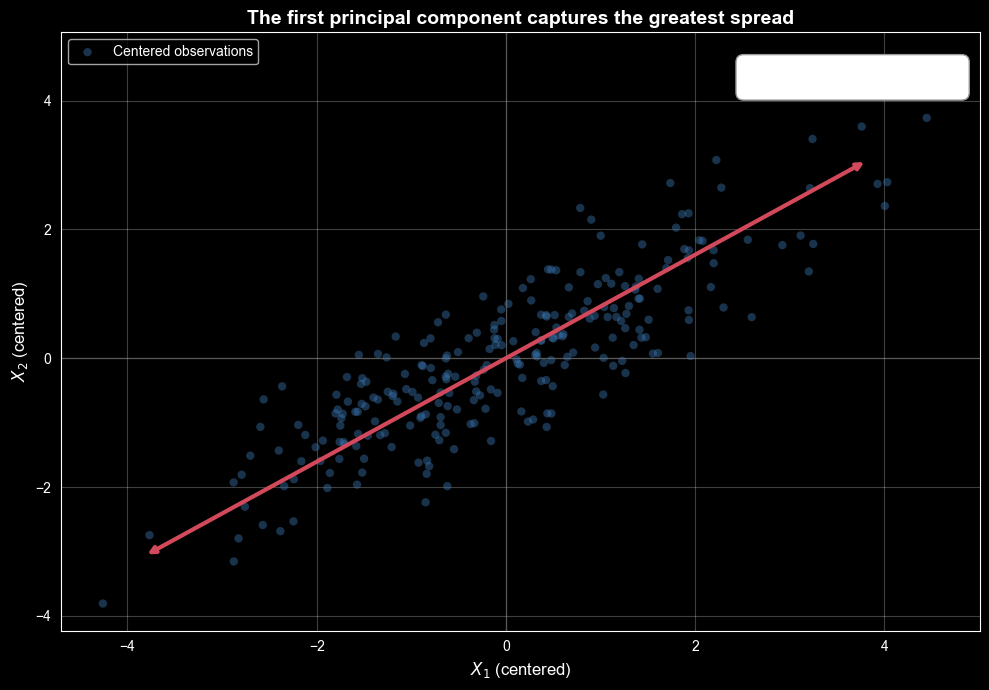

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Correlated, mean-centered example data
rng = np.random.default_rng(12)
cov = np.array([[3.0, 2.2],
                [2.2, 2.0]])
X = rng.multivariate_normal([0, 0], cov, size=250)
X -= X.mean(axis=0)

# Largest-eigenvalue eigenvector gives the first principal component
Sigma = np.cov(X, rowvar=False)
eigenvalues, eigenvectors = np.linalg.eigh(Sigma)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]
v1 = eigenvectors[:, 0]

# Keep the arrow pointing up and to the right for a consistent display
if v1[0] < 0:
    v1 = -v1

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(X[:, 0], X[:, 1], alpha=0.45, color="#3973ac",
           edgecolor="none", label="Centered observations")

# Show the first principal component direction
scale = 2.5 * np.sqrt(eigenvalues[0])
ax.annotate(
    "", xy=scale * v1, xytext=(-scale * v1),
    arrowprops=dict(arrowstyle="<->", color="#d1495b", lw=3)
)

ax.text(
    0.98, 0.95,
    f"PC1 direction = top eigenvector\n"
    f"Variance along PC1 = λ₁ ≈ {eigenvalues[0]:.2f}",
    transform=ax.transAxes, ha="right", va="top", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.5", facecolor="white", edgecolor="#999")
)

ax.set_title("The first principal component captures the greatest spread",
             fontsize=14, weight="bold")
ax.set_xlabel("$X_1$ (centered)", fontsize=12)
ax.set_ylabel("$X_2$ (centered)", fontsize=12)
ax.axhline(0, color="gray", lw=1, alpha=0.4)
ax.axvline(0, color="gray", lw=1, alpha=0.4)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()

## PCR with Multiple Principal Components
### 1. Choose multiple directions

For $M$ artificial inputs, PCA chooses $M$ directions that capture as much input variance as possible:

$$
\max_{\boldsymbol{\phi}_1,\ldots,\boldsymbol{\phi}_M}
\sum_{j=1}^{M}
\boldsymbol{\phi}_j^T\boldsymbol{\Sigma}_X\boldsymbol{\phi}_j
$$

subject to

$$
\|\boldsymbol{\phi}_j\|_2=1
\quad\text{and}\quad
\boldsymbol{\phi}_i^T\boldsymbol{\phi}_j=0
\ \text{for }i\ne j.
$$

The unit-length constraint prevents the weights from growing without limit. The orthogonality constraint makes the directions perpendicular, so they capture distinct directions in the input space.

The optimal directions are the unit eigenvectors of the covariance matrix, ordered by decreasing eigenvalue:

$$
\lambda_1\ge\lambda_2\ge\cdots\ge\lambda_p.
$$

The first $M$ eigenvectors give the first $M$ principal components.

### 2. Estimate the directions from data

Given $n$ input vectors $\mathbf{x}_1,\ldots,\mathbf{x}_n$, first center each input by subtracting the feature mean $\bar{\mathbf{x}}$. Estimate the covariance matrix with

$$
\widehat{\boldsymbol{\Sigma}}_X
=
\frac{1}{n-1}
\sum_{i=1}^{n}
(\mathbf{x}_i-\bar{\mathbf{x}})
(\mathbf{x}_i-\bar{\mathbf{x}})^T.
$$

Then find its eigenvectors $\mathbf{v}_1,\ldots,\mathbf{v}_p$, ordered by their eigenvalues from largest to smallest.

### 3. Reduce the inputs, then regress

For each centered input vector, keep its first $M$ component scores:

$$
\mathbf{z}_i =
\begin{bmatrix}
\mathbf{v}_1^T(\mathbf{x}_i-\bar{\mathbf{x}})\\
\mathbf{v}_2^T(\mathbf{x}_i-\bar{\mathbf{x}})\\
\vdots\\
\mathbf{v}_M^T(\mathbf{x}_i-\bar{\mathbf{x}})
\end{bmatrix}
\in\mathbb{R}^{M}.
$$

PCR fits a linear regression using these scores:

$$
\hat{y}_i
=
\hat{\theta}_0+
\hat{\theta}_1 z_{i1}+\cdots+\hat{\theta}_M z_{iM}.
$$

This replaces the original $p$ inputs with $M$ inputs, where $M<p$.

### Choosing $M$

- A small $M$ gives a simpler model: it may have higher bias and lower variance.
- A large $M$ keeps more information: bias may decrease while variance may increase.
- Choose $M$ using validation or cross-validation to find a good test-error tradeoff.
- PCA chooses directions using the inputs alone. A low-variance direction can still help predict the response, so PCR may discard useful information.

### Key Takeaways

- Principal components are perpendicular directions that capture input variance in descending order.
- PCR projects each observation onto the first $M$ principal components, then regresses the response on those scores.
- Increasing $M$ adds model flexibility; validation helps select a useful number of components.
- Center inputs before calculating PCA. Standardize features first when their scales differ substantially.

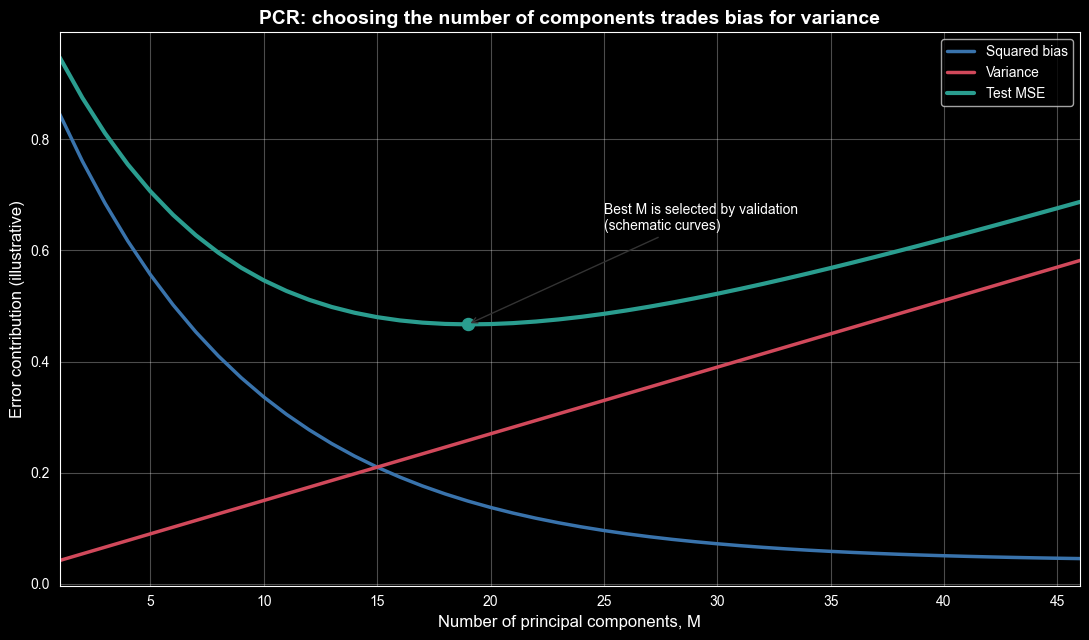

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Schematic curves: illustrative only, not measured results
M = np.arange(1, 47)
bias_squared = 0.9 * np.exp(-M / 9) + 0.04
variance = 0.012 * M + 0.03
test_mse = bias_squared + variance + 0.06

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.plot(M, bias_squared, lw=2.5, color="#3973ac", label="Squared bias")
ax.plot(M, variance, lw=2.5, color="#d1495b", label="Variance")
ax.plot(M, test_mse, lw=3, color="#2a9d8f", label="Test MSE")

best = np.argmin(test_mse)
ax.scatter(M[best], test_mse[best], s=75, color="#2a9d8f", zorder=3)
ax.annotate(
    "Best M is selected by validation\n(schematic curves)",
    xy=(M[best], test_mse[best]),
    xytext=(M[best] + 6, test_mse[best] + 0.17),
    arrowprops=dict(arrowstyle="->", color="#333"),
    fontsize=10
)

ax.set_title("PCR: choosing the number of components trades bias for variance",
             fontsize=14, weight="bold")
ax.set_xlabel("Number of principal components, M", fontsize=12)
ax.set_ylabel("Error contribution (illustrative)", fontsize=12)
ax.set_xlim(1, 46)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()